## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch 

from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split, ParameterGrid, KFold
from category_encoders import TargetEncoder
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning
import warnings
from sklearn.metrics import mean_squared_error, accuracy_score, brier_score_loss, log_loss
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance
from scipy.stats import norm

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

# Use a single CPU thread for PyTorch and NumPy: with several threads, sums are split up
# differently, so the results would depend on the number of cores of the machine
from threadpoolctl import threadpool_limits
torch.set_num_threads(1)
_ = threadpool_limits(1)

---
## Problem 1 — Modeling Conditional Mean and Standard Deviation

So far in this course we have focused on fitting models $f_\mu(x)$ to approximate $\mathbb{E}[Y \mid X]$, the conditional mean of the target $Y$ given the input $X$. Suppose we want to also incorporate a measure of uncertainty in our observations of $Y$, in the form of a function $f_\sigma(x) = \sqrt{\text{Var}(Y \mid X = x)}$ (the conditional standard deviation) which models how the observation noise changes with the input $X$.

### (a)
Say we have a neural architecture $g: \mathbb{R}^p \to \mathbb{R}^2$ that takes in a $p$-dimensional feature vector and returns a 2-dimensional vector of real numbers. Suggest a link function that would be appropriate for converting the output to $f_\mu$ and $f_\sigma$.

**Answer:**

Let the output be $g(x) = \begin{pmatrix} m_1(x) \\ m_2(x) \end{pmatrix}$, then a possible link function could be

$$h: \mathbb{R}^2 \to \mathbb{R} \times (0, \infty) \quad \text{with} \quad h(m_1, m_2) = \begin{pmatrix} m_1 \\ \exp(m_2) \end{pmatrix},$$

so that $f_\mu(x) = m_1(x)$ and $f_\sigma(x) = \exp(m_2(x)) = \sqrt{\text{Var}(Y \mid X = x)}$. Since the standard deviation must be positive, we ensure this by using $\exp()$ as the link, so $m_2(x)$ models the log standard deviation. This is not necessary for the mean, because it can be any real number.

### (b)
We could model data of this form as $Y \mid X \sim \mathcal{N}(f_\mu(X), f_\sigma(X)^2)$. Write down a loss function we could use for model training based on this model.

**Answer:**

The density of one observation is

$$f(y_i \mid x_i) = \frac{1}{\sqrt{2\pi} f_\sigma(x_i)} \exp\left( -\frac{(y_i - f_\mu(x_i))^2}{2 f_\sigma(x_i)^2} \right)$$

and the likelihood is

$$L_n(y \mid x) = \prod_{i=1}^{n} f(y_i \mid x_i)$$

with log-likelihood

$$
\begin{aligned}
\mathcal{L}_n(y \mid x) &= \sum_{i=1}^{n} \log\big( f(y_i \mid x_i) \big) \\
&= \sum_{i=1}^{n} \log\left( \frac{1}{\sqrt{2\pi} f_\sigma(x_i)} \exp\left( -\frac{(y_i - f_\mu(x_i))^2}{2 f_\sigma(x_i)^2} \right) \right) \\
&= \sum_{i=1}^{n} \left( -\frac{1}{2} \log(2\pi) - \log\big( f_\sigma(x_i) \big) - \frac{(y_i - f_\mu(x_i))^2}{2 f_\sigma(x_i)^2} \right).
\end{aligned}
$$

With the goal of maximizing the log-likelihood, i.e. minimizing the negative log-likelihood, and dropping terms independent of $f_\mu$ and $f_\sigma$, we obtain

$$\text{NLL} = -\mathcal{L}_n(y \mid x) = \sum_{i=1}^{n} \left( \log\big( f_\sigma(x_i) \big) + \frac{(y_i - f_\mu(x_i))^2}{2 f_\sigma(x_i)^2} \right).$$

Using the proposed link function from (a),

$$\text{NLL} = \sum_{i=1}^{n} \left( m_2(x_i) + \frac{1}{2} \big( y_i - m_1(x_i) \big)^2 \exp\big( -2 m_2(x_i) \big) \right).$$

### (c)
We have provided a dataset from taxi trips taken in NYC in `taxi_trips.parquet`. It contains 8 total columns, 7 features and 1 target (`trip_duration`, in minutes). The 7 features (pickup/dropoff coordinates and time-of-day, day-of-week and day-of-year) have already been standardized, so do not expect them to look like raw latitudes and longitudes. Define a multi-layer perceptron in PyTorch or JAX that outputs a conditional mean and standard deviation, and fit this on the taxi trip dataset. Make sure to follow best practices: define a baseline (or multiple) baseline models that you think your model should beat, split your dataset into training/validation/test sets, etc.

**Load & explore data**

In [2]:
taxi_trips_data = pd.read_parquet('taxi_trips.parquet')

taxi_trips_data.head()

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,min_of_day,day_of_week,day_of_year
187173,0.270744,1.425051,0.466831,0.776192,7.965142,-0.942057,-1.047619,1.180855
179655,0.085681,0.306079,-0.226274,0.124111,10.680277,0.778703,-1.047619,-0.311290
120048,-0.555533,-0.934806,-0.022489,-0.548561,5.716184,-1.183016,-1.047619,1.316504
62587,0.069718,0.035804,0.258900,0.317284,4.266709,-0.908008,0.481657,0.018144
212063,-0.234482,0.074616,0.115836,0.258310,11.629685,1.066806,-0.537860,0.521985


**Preprocessing & train / validation / test split**

**Why preprocess at all?**

In principle, the MLP could learn the distance, cyclical time of the day and the weekday effects from the raw inputs, since it is a universal approximator. However, with the limited training data and training time, this inductive bias should help, because the model can learn from features that already encode this structure. More importantly, the baselines cannot learn it at all, especially the linear model. Since the same features are used for all models, the comparison reflects the models rather than their inputs.

**Preprocessing choices**

All features except `trip_duration` are already standardized. Looking at the data, we make the following choices:

1. **`day_of_week` is one-hot encoded.** It only takes 7 distinct values, and its effect on the trip duration is not monotonic: trips are longest in the middle of the week (about 11.1 minutes on average on Thursdays) and shortest at the end of the week (about 9.4 on Sundays; see choice 5 for how we know the weekdays). A single numeric feature forces e.g. the linear model to treat this as a straight line, so we encode it as a categorical variable (6 dummy variables, with Monday as the reference category).
2. **`min_of_day` is replaced by $\sin(2\pi t / 1440)$ and $\cos(2\pi t / 1440)$**, where $t \in \{0, \dots, 1439\}$ is the minute of the day. As a single number, 23:59 and 00:00 lie at opposite ends of the scale, although trips at both times behave almost the same. The sine/cosine encoding places the minutes on a circle, so that times just before and just after midnight are close to each other. Since the column has exactly 1,440 distinct values, we can recover $t$ from the order of the standardized values.
3. **Trips with extreme coordinates are kept.** 79 trips have a coordinate beyond ±10 standard deviations, and about 4,700 more lie between 5 and 10 standard deviations, most likely airport trips (median 24.7 minutes vs. 8.6 overall). We checked whether the most extreme trips are GPS errors by comparing their implied speed (straight-line distance divided by duration) with that of the 5–10 group: trips with one end beyond ±10 standard deviations are only slightly faster (median 0.24 vs. 0.19 standardized units per minute), consistent with real trips into or out of the city, partly on highways. Trips with both ends that far out are short and often take almost no time, but they are only 36 trips. Location alone therefore does not separate erroneous from real trips, so we keep all trips. Since only 79 of more than 500,000 trips are affected, this choice has a negligible effect on the results.

4. **A distance feature is added**: the straight-line distance between pickup and dropoff, $\sqrt{(\Delta\text{longitude})^2 + (\Delta\text{latitude})^2}$. The trip duration mainly depends on the distance travelled, which is not a linear function of the coordinates, so e.g. the linear model cannot learn it on its own. This is **only an approximation** of the actual distance: it is computed in the standardized coordinates rather than in kilometers (longitude and latitude were standardized separately, so one unit in each direction corresponds to a different real distance), and the taxi follows the street network rather than a straight line.

5. **`day_of_year` is kept as a continuous feature** (182 distinct values, i.e. about half a year). The days most likely correspond to 1 January to 30 June 2016: the data starts on a Friday (so `day_of_week` runs from Monday to Sunday), and known events fall on the right dates, e.g. the fewest trips are on 23 January 2016, the day of the New York blizzard. Since weekdays and weekends have different trip durations, we look at the effect of `day_of_year` after accounting for the day of the week, using the Frisch–Waugh–Lovell theorem: we regress both the trip duration and `day_of_year` on the weekday dummies and plot the residuals against each other. The partial effect is a clear, roughly linear upward trend of about 0.22 minutes per 30 days (the slope equals the `day_of_year` coefficient in the regression of the trip duration on `day_of_year` and the weekday dummies), plus short spikes on individual days, such as the days after the blizzard and holidays. A continuous feature captures this trend directly, while 182 categories would mostly memorize individual days and could not generalize to new dates. A cyclical encoding is not appropriate either: the data only covers half a year, so its first and last days are not neighbours.

The same features are used for all models, including the baselines.

**Evidence 1: `day_of_week` — 7 distinct values and a non-monotonic effect on the trip duration**

In [3]:
day = taxi_trips_data['day_of_week'].rank(method='dense').astype(int)
taxi_trips_data.groupby(day)['trip_duration'].agg(['mean', 'count'])

,mean,count
day_of_week,,
1,9.906322,68171
2,10.692038,72747
3,10.975804,74143
4,11.146613,77276
5,10.791919,79981
6,9.913843,80677
7,9.361565,70559


**Evidence 2: `min_of_day` — 1,440 distinct values and similar trip durations just before and after midnight**

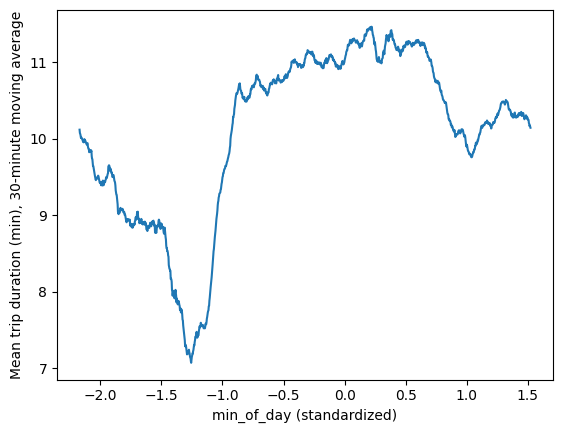

Distinct values of min_of_day: 1440


In [4]:
taxi_trips_data.groupby('min_of_day')['trip_duration'].mean().rolling(30, center=True).mean().plot()
plt.xlabel('min_of_day (standardized)')
plt.ylabel('Mean trip duration (min), 30-minute moving average')
plt.show()

print(f'Distinct values of min_of_day: {taxi_trips_data["min_of_day"].nunique()}')

**Evidence 3: extreme coordinates — implied speed of trips beyond ±10 standard deviations vs. the airport cluster between 5 and 10**

In [5]:
# largest absolute coordinate at each end of the trip
pickup_extreme = taxi_trips_data[['pickup_longitude', 'pickup_latitude']].abs().max(axis=1)
dropoff_extreme = taxi_trips_data[['dropoff_longitude', 'dropoff_latitude']].abs().max(axis=1)
most_extreme = np.maximum(pickup_extreme, dropoff_extreme)

# implied speed: straight-line distance (in standardized units) per minute
distance = np.sqrt(
  (taxi_trips_data['dropoff_longitude'] - taxi_trips_data['pickup_longitude']) ** 2
  + (taxi_trips_data['dropoff_latitude'] - taxi_trips_data['pickup_latitude']) ** 2)
speed = distance / taxi_trips_data['trip_duration']

groups = {
  'all coordinates within +-5 SD': most_extreme <= 5,
  '5-10 SD (airport cluster)': (most_extreme > 5) & (most_extreme <= 10),
  'one end beyond +-10 SD': (pickup_extreme > 10) ^ (dropoff_extreme > 10),
  'both ends beyond +-10 SD': (pickup_extreme > 10) & (dropoff_extreme > 10)
}

pd.DataFrame({
  name: {
    'trips': mask.sum(),
    'median distance': distance[mask].median(),
    'median duration (min)': taxi_trips_data['trip_duration'][mask].median(),
    'speed 25%': speed[mask].quantile(0.25),
    'speed median': speed[mask].median(),
    'speed 75%': speed[mask].quantile(0.75),
    'speed 90%': speed[mask].quantile(0.90)
  } for name, mask in groups.items()
}).T.round(3)

,trips,median distance,median duration (min),speed 25%,speed median,speed 75%,speed 90%
all coordinates within +-5 SD,518734.0,0.642,8.581,0.059,0.082,0.112,0.149
5-10 SD (airport cluster),4741.0,5.187,24.703,0.142,0.188,0.258,0.457
one end beyond +-10 SD,43.0,4.867,21.855,0.188,0.241,0.291,0.464
both ends beyond +-10 SD,36.0,0.340,1.251,0.102,0.315,0.805,1.556


**Evidence 4: distance — trip duration vs. straight-line distance between pickup and dropoff**

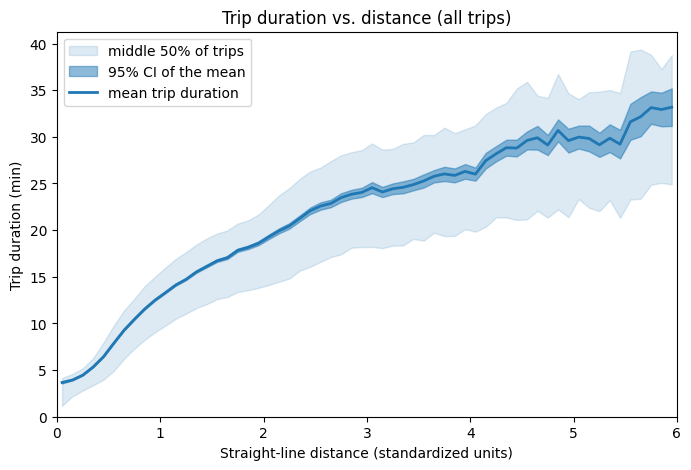

Correlation between distance and trip duration: 0.72


In [6]:
# uses `distance` from Evidence 3
# mean trip duration in 60 distance bins, using all trips
bins = np.linspace(0, 6, 61)
stats = taxi_trips_data['trip_duration'].groupby(pd.cut(distance, bins), observed=True).agg(
  ['mean', 'std', 'count', lambda d: d.quantile(0.25), lambda d: d.quantile(0.75)])
stats.columns = ['mean', 'std', 'count', 'q25', 'q75']
centers = np.array([interval.mid for interval in stats.index])

# 95% confidence interval of the mean in each bin
ci = 1.96 * stats['std'] / np.sqrt(stats['count'])

plt.figure(figsize=(8, 5))
plt.fill_between(centers, stats['q25'], stats['q75'], color='tab:blue', alpha=0.15, label='middle 50% of trips')
plt.fill_between(centers, stats['mean'] - ci, stats['mean'] + ci, color='tab:blue', alpha=0.5, label='95% CI of the mean')
plt.plot(centers, stats['mean'], color='tab:blue', linewidth=2, label='mean trip duration')
plt.xlim(0, 6)
plt.ylim(0, None)
plt.xlabel('Straight-line distance (standardized units)')
plt.ylabel('Trip duration (min)')
plt.title('Trip duration vs. distance (all trips)')
plt.legend(loc='upper left')
plt.show()

print(f'Correlation between distance and trip duration: {np.corrcoef(distance, taxi_trips_data["trip_duration"])[0, 1]:.2f}')

**Evidence 5: `day_of_year` — 182 distinct values and its effect on the trip duration after accounting for `day_of_week` (Frisch–Waugh–Lovell)**

FWL slope: 0.00731 min per day, full regression coefficient: 0.00731


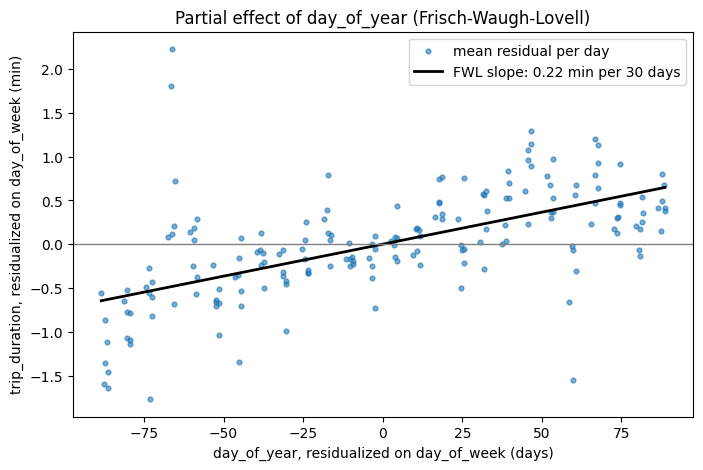

In [7]:
# Frisch-Waugh-Lovell: partial out day_of_week from both the target and day_of_year
weekday = taxi_trips_data['day_of_week'].rank(method='dense').astype(int)            # 1 = Monday, ..., 7 = Sunday
day_number = taxi_trips_data['day_of_year'].rank(method='dense').astype(int) - 1     # 0 = 1 January 2016
W = pd.get_dummies(weekday, dtype=float).values                                       # weekday dummies (incl. intercept)

def residualize(v):
  """Residuals of an OLS regression of v on the weekday dummies."""
  coef, *_ = np.linalg.lstsq(W, v, rcond=None)
  return v - W @ coef

duration_resid = residualize(taxi_trips_data['trip_duration'].values)
day_resid = residualize(day_number.values.astype(float))

# FWL: the slope of duration_resid on day_resid equals the day_of_year coefficient
# in the full regression trip_duration ~ day_of_year + weekday dummies
slope = (day_resid @ duration_resid) / (day_resid @ day_resid)
full_coef, *_ = np.linalg.lstsq(np.column_stack([day_number, W]), taxi_trips_data['trip_duration'].values, rcond=None)
print(f'FWL slope: {slope:.5f} min per day, full regression coefficient: {full_coef[0]:.5f}')

# one point per day: all trips of a day share the same day_resid
daily_resid = pd.DataFrame({'day_resid': day_resid, 'duration_resid': duration_resid}).groupby(day_number.values).mean()

plt.figure(figsize=(8, 5))
plt.scatter(daily_resid['day_resid'], daily_resid['duration_resid'], s=12, alpha=0.6, label='mean residual per day')
x_line = np.array([daily_resid['day_resid'].min(), daily_resid['day_resid'].max()])
plt.plot(x_line, slope * x_line, color='black', linewidth=2, label=f'FWL slope: {30 * slope:.2f} min per 30 days')
plt.axhline(0, color='grey', linewidth=1)
plt.xlabel('day_of_year, residualized on day_of_week (days)')
plt.ylabel('trip_duration, residualized on day_of_week (min)')
plt.title('Partial effect of day_of_year (Frisch-Waugh-Lovell)')
plt.legend()
plt.show()

In [8]:
taxi_features = taxi_trips_data.drop(columns='trip_duration')
y_taxi = taxi_trips_data['trip_duration']

# minute of the day t = 0, ..., 1439 (the standardized column has exactly 1,440 distinct values, in the same order)
minute_of_day = taxi_features['min_of_day'].rank(method='dense').astype(int) - 1
assert minute_of_day.max() == 1439

# cyclical encoding, so that 23:59 and 00:00 are close to each other
taxi_features['min_of_day_sin'] = np.sin(2 * np.pi * minute_of_day / 1440)
taxi_features['min_of_day_cos'] = np.cos(2 * np.pi * minute_of_day / 1440)

# day of the week as a category (0, ..., 6), one-hot encoded with the first day as reference
day_of_week = taxi_features['day_of_week'].rank(method='dense').astype(int) - 1
assert day_of_week.max() == 6
day_of_week_dummies = pd.get_dummies(day_of_week, prefix='day_of_week', drop_first=True, dtype=float)

# straight-line distance between pickup and dropoff; only an approximation of the real distance,
# since it is computed in standardized coordinates and taxis follow the streets
taxi_features['distance'] = np.sqrt(
    (taxi_features['dropoff_longitude'] - taxi_features['pickup_longitude']) ** 2
    + (taxi_features['dropoff_latitude'] - taxi_features['pickup_latitude']) ** 2)

X_taxi = pd.concat([taxi_features.drop(columns=['min_of_day', 'day_of_week']), day_of_week_dummies], axis=1)
print(f'Features: {list(X_taxi.columns)}')

# 20% test, then 10% of the total (= 12.5% of the remaining 80%) for validation
X_train_val_taxi, X_test_taxi, y_train_val_taxi, y_test_taxi = train_test_split(
    X_taxi, y_taxi, test_size=0.2, random_state=RANDOM_STATE)
X_train_taxi, X_val_taxi, y_train_taxi, y_val_taxi = train_test_split(
    X_train_val_taxi, y_train_val_taxi, test_size=0.125, random_state=RANDOM_STATE)

print(f'Train: {len(X_train_taxi)} ({len(X_train_taxi)/len(X_taxi):.0%})')
print(f'Val:   {len(X_val_taxi)} ({len(X_val_taxi)/len(X_taxi):.0%})')
print(f'Test:  {len(X_test_taxi)} ({len(X_test_taxi)/len(X_taxi):.0%})')

# float32 tensors for PyTorch
def to_tensor(df):
    return torch.tensor(df.values, dtype=torch.float32)

X_train_t, y_train_t = to_tensor(X_train_taxi), to_tensor(y_train_taxi)
X_val_t, y_val_t = to_tensor(X_val_taxi), to_tensor(y_val_taxi)
X_test_t, y_test_t = to_tensor(X_test_taxi), to_tensor(y_test_taxi)

Features: ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'day_of_year', 'min_of_day_sin', 'min_of_day_cos', 'distance', 'day_of_week_1', 'day_of_week_2', 'day_of_week_3', 'day_of_week_4', 'day_of_week_5', 'day_of_week_6']
Train: 366487 (70%)
Val:   52356 (10%)
Test:  104711 (20%)


**Baseline model(s)**

In [9]:
# Baseline 0: always predict the mean trip duration of the training set
mean_test_mse = mean_squared_error(y_test_taxi, np.full(len(y_test_taxi), y_train_taxi.mean()))

# Baseline 1: linear regression
lin_reg = LinearRegression()
lin_reg.fit(X_train_taxi, y_train_taxi)
lin_test_mse = mean_squared_error(y_test_taxi, lin_reg.predict(X_test_taxi))

# Baseline 2: random forest
rf = RandomForestRegressor(
  n_estimators = 100,
  n_jobs = -1,
  random_state = RANDOM_STATE
)
rf.fit(X_train_taxi, y_train_taxi)
rf_test_mse = mean_squared_error(y_test_taxi, rf.predict(X_test_taxi))

print(f'Training mean test MSE:     {mean_test_mse:.4f}')
print(f'Linear regression test MSE: {lin_test_mse:.4f}')
print(f'Random forest test MSE:     {rf_test_mse:.4f}')

Training mean test MSE:     59.3744
Linear regression test MSE: 24.9410
Random forest test MSE:     15.2738


**MLP definition (outputs mean and standard deviation)**

In [10]:
class MLP(nn.Module):
  def __init__(self, in_dim, hidden_dim=512, n_hidden=4):
    super().__init__()
    layers = []
    for i in range(n_hidden):
      layers += [nn.Linear(in_dim if i == 0 else hidden_dim, hidden_dim), nn.ReLU()]
    layers.append(nn.Linear(hidden_dim, 2))
    self.net = nn.Sequential(*layers)

  def forward(self, x):
    out = self.net(x)
    mu = out[:, 0]
    log_sigma = out[:, 1].clamp(-50, 50)  # keeps exp(2 * log_sigma) from overflowing to inf
    return mu, log_sigma

**Training**

In [11]:
# GaussianNLLLoss takes the variance, i.e. f_sigma(x)^2 = exp(2 * log_sigma)
loss_fn = nn.GaussianNLLLoss()

# CPU, so that the results do not depend on whether a GPU is available
# (GPU and CPU round slightly differently; the CPU is not slower here)
device = 'cpu'
torch.manual_seed(RANDOM_STATE)

# standardize the target for training; predictions are transformed back for evaluation
y_mean, y_std = y_train_t.mean(), y_train_t.std()

X_tr, y_tr = X_train_t.to(device), ((y_train_t - y_mean) / y_std).to(device)
X_va, y_va = X_val_t.to(device), y_val_t.to(device)

def predict(model, X):
  """Mean and standard deviation on the original scale (minutes)."""
  model.eval()
  with torch.no_grad():
    mu, log_sigma = model(X)
  return mu * y_std + y_mean, torch.exp(log_sigma) * y_std

batch_size = 2048
max_epochs = 100
patience = 8
steps_per_epoch = (len(X_tr) + batch_size - 1) // batch_size

model = MLP(in_dim=X_tr.shape[1]).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
  optimizer, max_lr=1e-3, total_steps=max_epochs * steps_per_epoch)

best_val_loss = float('inf')
best_epoch = 0

for epoch in range(max_epochs):
  model.train()
  perm = torch.randperm(len(X_tr), device=device)
  for k in range(steps_per_epoch):
    idx = perm[k * batch_size:(k + 1) * batch_size]
    optimizer.zero_grad()
    mu, log_sigma = model(X_tr[idx])
    loss = loss_fn(mu, y_tr[idx], torch.exp(2 * log_sigma))
    loss.backward()
    optimizer.step()
    scheduler.step()

  mu_val, sigma_val = predict(model, X_va)
  val_loss = loss_fn(mu_val, y_va, sigma_val ** 2).item()
  val_mse = torch.mean((mu_val - y_va) ** 2).item()
  print(f'Epoch {epoch + 1}: val NLL {val_loss:.4f}, val MSE {val_mse:.3f}')

  # early stopping on the validation NLL
  if val_loss < best_val_loss:
    best_val_loss = val_loss
    best_state = {k: v.clone() for k, v in model.state_dict().items()}
    best_epoch = epoch
  elif epoch - best_epoch >= patience:
    print('Early stopping')
    break

model.load_state_dict(best_state)
print(f'Best epoch: {best_epoch + 1}')

Epoch 1: val NLL 2.0054, val MSE 23.525


Epoch 2: val NLL 1.9329, val MSE 22.264


Epoch 3: val NLL 2.0125, val MSE 24.122


Epoch 4: val NLL 1.8438, val MSE 18.578


Epoch 5: val NLL 1.8080, val MSE 17.481


Epoch 6: val NLL 1.7918, val MSE 16.849


... (42 outputs left out)

Epoch 49: val NLL 1.6803, val MSE 12.799


Epoch 50: val NLL 1.6959, val MSE 12.876


Epoch 51: val NLL 1.6865, val MSE 12.760


Epoch 52: val NLL 1.7070, val MSE 13.069
Early stopping
Best epoch: 44


**Evaluation & comparison to baselines**

In [12]:
mu_test, sigma_test = predict(model, X_test_t.to(device))
mu_test, sigma_test = mu_test.cpu(), sigma_test.cpu()

test_mse = torch.mean((mu_test - y_test_t) ** 2).item()
test_nll = loss_fn(mu_test, y_test_t, sigma_test ** 2).item()

# NLL of a constant normal distribution with the training mean and standard deviation
const_nll = loss_fn(torch.full_like(y_test_t, y_train_taxi.mean()), y_test_t,
                    torch.full_like(y_test_t, y_train_taxi.var())).item()

print(f'MLP test MSE:               {test_mse:.4f}')
print(f'MLP test NLL:               {test_nll:.4f}')
print(f'Constant normal test NLL:   {const_nll:.4f}')
print(f'Training mean test MSE:     {mean_test_mse:.4f}')
print(f'Linear regression test MSE: {lin_test_mse:.4f}')
print(f'Random forest test MSE:     {rf_test_mse:.4f}')

MLP test MSE:               13.8842
MLP test NLL:               1.7865
Constant normal test NLL:   2.5420
Training mean test MSE:     59.3744
Linear regression test MSE: 24.9410
Random forest test MSE:     15.2738


**Discussion:**

The MLP is far better than predicting the training mean or using linear regression, and also beats an untuned random forest (test MSE 13.88 vs. 15.27, about 9% lower). Its NLL is also much lower than that of a single normal distribution fitted to the training targets, so the predicted standard deviations capture how the noise changes with the input.

### (d)
How would we use the model we've just fit to predict the probability that a trip will take less than 45 minutes? The normal distribution assumption is fine.

**Answer:**

Suppose we wanted to predict the probability that a trip, represented by covariates $X_i$, will take less than 45 minutes. Let $\hat{f}_\mu (X_i)$ and $\hat{f}_\sigma (X_i)$ be the outputs from the MLP, then

$$ Y_i \mid X_i \approx \mathcal{N}\left(\hat{f}_\mu (X_i), \hat{f}_\sigma (X_i)^2\right)$$

and, since $\hat{f}_\sigma$ is the standard deviation, we standardize:

$$ P \left( Y_i \le 45 \mid X_i \right) = P \left( \frac{Y_i - \hat{f}_\mu (X_i)}{\hat{f}_\sigma (X_i)} \le \frac{45 - \hat{f}_\mu (X_i)}{\hat{f}_\sigma (X_i)} \right) \approx \Phi \left(  \frac{45 - \hat{f}_\mu (X_i)}{\hat{f}_\sigma (X_i)} \right), $$

where $\Phi$ is the CDF of the standard normal distribution. Since the normal distribution is continuous, $P(Y_i < 45 \mid X_i) = P(Y_i \le 45 \mid X_i)$, so this is also the probability that the trip takes strictly less than 45 minutes.

### (e)
Estimate these probabilities on your held-out test set and evaluate them. Report both a proper scoring rule for the predicted probabilities (e.g. the Brier score or the log-loss) and the classification accuracy obtained by thresholding the probability at 0.5.

In [13]:
mu_test, sigma_test = predict(model, X_test_t.to(device))
mu_test, sigma_test = mu_test.cpu().numpy(), sigma_test.cpu().numpy()

# P(Y < 45 | X) = Phi((45 - f_mu(X)) / f_sigma(X))
p_under_45 = norm.cdf((45 - mu_test) / sigma_test)

y_under_45 = y_test_t.numpy() < 45       # actual outcome
y_pred_under_45 = p_under_45 >= 0.5      # predicted outcome

# reference: the same constant probability for every trip (share of training trips under 45 minutes)
p_const = np.full(len(y_under_45), (y_train_taxi.values < 45).mean())

print(f'Brier score:                     {brier_score_loss(y_under_45, p_under_45):.4f}')
print(f'Brier score of constant p:       {brier_score_loss(y_under_45, p_const):.4f}')
print(f'Log-loss:                        {log_loss(y_under_45, np.clip(p_under_45, 1e-15, 1 - 1e-15)):.4f}')
print(f'Log-loss of constant p:          {log_loss(y_under_45, p_const):.4f}')
print(f'Accuracy (threshold 0.5):        {accuracy_score(y_under_45, y_pred_under_45):.4f}')
print(f'Accuracy of always "under 45":   {y_under_45.mean():.4f}')
print(f'Mean predicted P(Y < 45):        {p_under_45.mean():.4f}')
print(f'Actual share of trips < 45 min:  {y_under_45.mean():.4f}')

Brier score:                     0.0029
Brier score of constant p:       0.0045
Log-loss:                        0.0234
Log-loss of constant p:          0.0291
Accuracy (threshold 0.5):        0.9964
Accuracy of always "under 45":   0.9954
Mean predicted P(Y < 45):        0.9961
Actual share of trips < 45 min:  0.9954


**Results:**

| Predictor | Brier score | Log-loss | Accuracy (threshold 0.5) |
|---|---|---|---|
| MLP, $\Phi\big((45 - \hat{f}_\mu) / \hat{f}_\sigma\big)$ | 0.0029 | 0.0234 | 0.9964 |
| Constant $p$ = share of training trips under 45 min | 0.0045 | 0.0291 | 0.9954 |

Both proper scoring rules are clearly better than for the constant probability (about 36% lower Brier score and 20% lower log-loss), so the predicted probabilities carry real information about which trips run long. The model is also well calibrated on average: the mean predicted probability (0.9961) is almost exactly the actual share of trips under 45 minutes (0.9954).

The accuracy, on the other hand, is not very informative: 99.5% of the test trips take less than 45 minutes, so always predicting "under 45" already achieves 0.9954, and thresholding the MLP's probabilities only improves this slightly, to 0.9964. With such imbalanced classes, the proper scoring rules are the better way to evaluate the predicted probabilities.

---
## Problem 2 — Encoding Categorical Variables

For this problem, you will explore different methods for encoding categorical random variables. We have provided a dataset `retail.csv`, which contains data on retail transactions. We've cleaned up the data a bit so you only have two features: `StockCode` and `CustomerID`, both of which are categorical. (You may need to convert them to categorical data types in your code for the encoding methods to work properly.) The target is `Quantity`, which is a positive integer. Note that `Quantity` is very heavy-tailed (most values are small, but a few are enormous), so think about what loss function and/or target transformation is appropriate.

### (a)
Start by exploring the cardinality of the two features. How many unique values are there for each feature? What does this suggest about how you might encode them? Is one-hot encoding feasible?

To prepare for the next steps, split the data into training, validation, and test sets. The validation set will allow you to use early stopping during training for the neural network models.

**Load data & explore cardinality**

In [14]:
retail_data = pd.read_csv('retail.csv',
                          dtype = {'Quantity': np.int64,
                                   'StockCode': 'category',
                                   'CustomerID': 'category'})

print('Number of categories in StockCode: {}'.format(
  len(retail_data.StockCode.unique())
))

print('Number of categories in CustomerID: {}'.format(
  len(retail_data.CustomerID.unique())
))

print(retail_data.Quantity.describe(percentiles = [0.5, 0.9, 0.99, 0.999]))

Number of categories in StockCode: 3665
Number of categories in CustomerID: 4339
count    397924.000000
mean         13.021823
std         180.420210
min           1.000000
50%           6.000000
90%          24.000000
99%         120.000000
99.9%       504.000000
max       80995.000000
Name: Quantity, dtype: float64


**Answer:**

StockCode has 3665 unique values and CustomerID has 4339 unique values. Because of their high cardinality, one-hot encoding is not really feasible: it would create about 8,000 sparse columns, most of which only have a handful of observations. This suggests a lower-dimensional encoding, such as target encoding (one number per category) or learned embeddings. Target encoding uses the target to build the features, so we have to be careful that a row's own `Quantity` does not leak into its features.

`Quantity` is a count with a very heavy tail (the median is 6, but the maximum is 80,995). A squared-error loss would be dominated by the few enormous orders, so we instead model it as a count with a log link and use the Poisson loss (equivalently, the models predict $\log \mathbb{E}[\text{Quantity} \mid X]$), which grows much more slowly in the size of the errors for large values.

**Train / validation / test split**

In [15]:
X_retail = retail_data[['StockCode', 'CustomerID']]
y_retail = retail_data['Quantity']

# 20% test, then 10% of the total (= 12.5% of the remaining 80%) for validation
X_train_val_retail, X_test_retail, y_train_val_retail, y_test_retail = train_test_split(
    X_retail, y_retail, test_size=0.2, random_state=RANDOM_STATE)
X_train_retail, X_val_retail, y_train_retail, y_val_retail = train_test_split(
    X_train_val_retail, y_train_val_retail, test_size=0.125, random_state=RANDOM_STATE)

print(f'Train: {len(X_train_retail)} ({len(X_train_retail)/len(X_retail):.0%})')
print(f'Val:   {len(X_val_retail)} ({len(X_val_retail)/len(X_retail):.0%})')
print(f'Test:  {len(X_test_retail)} ({len(X_test_retail)/len(X_retail):.0%})')

Train: 278546 (70%)
Val:   39793 (10%)
Test:  79585 (20%)


### (b)
Try target encoding. For each unique value of the feature, replace it with the mean of the target for that value (from the training set). You can use `TargetEncoder` from the `category_encoders` package. Using an appropriate loss function, fit a model of your choice to the data using the target-encoded features. Evaluate the model on the test set.

In [16]:
cat_cols = ['StockCode', 'CustomerID']

# Out-of-fold target encoding for the training rows: each row is encoded with category means
# from the other folds, so its own Quantity does not leak into its features.
X_train_encoded = pd.DataFrame(index = X_train_retail.index, columns = cat_cols, dtype = float)
for fit_idx, enc_idx in KFold(n_splits = 5, shuffle = True, random_state = RANDOM_STATE).split(X_train_retail):
  fold_enc = TargetEncoder(cols = cat_cols)
  fold_enc.fit(X_train_retail.iloc[fit_idx], y_train_retail.iloc[fit_idx])
  X_train_encoded.iloc[enc_idx] = fold_enc.transform(X_train_retail.iloc[enc_idx]).values

# validation and test rows: encoder fitted on the full training set
enc = TargetEncoder(cols = cat_cols)
enc.fit(X_train_retail, y_train_retail)
X_val_encoded = enc.transform(X_val_retail)
X_test_encoded = enc.transform(X_test_retail)

# Quantity is a count, so we use the Poisson criterion
model_5b = RandomForestRegressor(
  n_estimators = 100,
  criterion = 'poisson',
  n_jobs = -1,
  max_samples = 0.2,
  min_samples_leaf = 40,
  random_state = RANDOM_STATE
)
model_5b.fit(X_train_encoded, y_train_retail)

retail_results = {}

def evaluate_retail(name, y_pred):
  y_pred = np.clip(y_pred, 1e-6, None)  # Poisson deviance needs positive predictions
  retail_results[name] = {
    'test_mse': mean_squared_error(y_test_retail, y_pred),
    'test_mae': mean_absolute_error(y_test_retail, y_pred),
    'test_poisson_deviance': mean_poisson_deviance(y_test_retail, y_pred)
  }
  return pd.DataFrame(retail_results).T

evaluate_retail('Training mean', np.full(len(y_test_retail), y_train_retail.mean()))
evaluate_retail('Target encoding + RF', model_5b.predict(X_test_encoded))

,test_mse,test_mae,test_poisson_deviance
Training mean,1646.690949,12.686307,26.087709
Target encoding + RF,1196.438425,7.936776,9.571388


**Results:**

Since `Quantity` is a count, we use a random forest with the Poisson splitting criterion on the two target-encoded features. The training rows are target-encoded out-of-fold (5 folds), so that a row's own `Quantity` does not leak into its features; validation and test rows are encoded with the encoder fitted on the full training set.

| Model | Test MSE | Test MAE | Test Poisson deviance |
|---|---|---|---|
| Training mean | 1646.7 | 12.69 | 26.09 |
| Target encoding + RF | 1196.4 | 7.94 | 9.57 |

The model clearly improves on predicting the training mean. The MSE is still large because `Quantity` is extremely heavy-tailed (median 6, maximum 80,995), so a handful of very large orders dominate the squared error.

### (c)
Try a neural network model with an embedding layer for each of the two features. Choose a reasonable embedding dimension. Fit this model to the data. Evaluate the model on the test set. How does it compare to the target encoding model?

In [17]:
# map each category to an integer index; index 0 is reserved for categories not seen in training
cat_index = {col: {cat: i + 1 for i, cat in enumerate(X_train_retail[col].unique())} for col in cat_cols}

def to_codes(X):
  return torch.tensor(np.stack(
    [X[col].map(cat_index[col]).astype(float).fillna(0).astype(int).values for col in cat_cols], axis = 1))

C_train, C_val, C_test = to_codes(X_train_retail), to_codes(X_val_retail), to_codes(X_test_retail)

# standardized log target encodings (used in part (d))
log_te_train = np.log(X_train_encoded.values.astype(float))
te_mean, te_std = log_te_train.mean(axis = 0), log_te_train.std(axis = 0)

def to_te(X_encoded):
  return torch.tensor((np.log(X_encoded.values.astype(float)) - te_mean) / te_std, dtype = torch.float32)

T_train, T_val, T_test = to_te(X_train_encoded), to_te(X_val_encoded), to_te(X_test_encoded)
q_train = torch.tensor(y_train_retail.values, dtype = torch.float32)
q_val = torch.tensor(y_val_retail.values, dtype = torch.float32)


class EmbeddingNet(nn.Module):
  """Embedding for each feature (optionally plus target encodings) -> MLP -> log of the expected Quantity."""

  def __init__(self, embedding_dim = 16, use_target_encoding = False, hidden_dim = 128):
    super().__init__()
    self.use_target_encoding = use_target_encoding
    self.stock_embedding = nn.Embedding(len(cat_index['StockCode']) + 1, embedding_dim)
    self.customer_embedding = nn.Embedding(len(cat_index['CustomerID']) + 1, embedding_dim)

    in_dim = 2 * embedding_dim + (2 if use_target_encoding else 0)
    self.mlp = nn.Sequential(
      nn.Linear(in_dim, hidden_dim),
      nn.ReLU(),
      nn.Linear(hidden_dim, hidden_dim),
      nn.ReLU(),
      nn.Linear(hidden_dim, 1)
    )
    # start by predicting the training mean for every row
    nn.init.zeros_(self.mlp[-1].weight)
    nn.init.constant_(self.mlp[-1].bias, float(np.log(y_train_retail.mean())))

  def forward(self, codes, target_encoding):
    inputs = [self.stock_embedding(codes[:, 0]), self.customer_embedding(codes[:, 1])]
    if self.use_target_encoding:
      inputs.append(target_encoding)
    return self.mlp(torch.cat(inputs, dim = 1)).squeeze(-1)


def train_embedding_net(model, max_epochs = 50, patience = 5, batch_size = 1024):
  # Poisson NLL on the log scale, since Quantity is a count
  poisson_loss = nn.PoissonNLLLoss(log_input = True)
  optimizer = torch.optim.AdamW(model.parameters(), lr = 1e-3, weight_decay = 1e-2)
  best_val_loss, best_epoch = float('inf'), 0

  for epoch in range(max_epochs):
    model.train()
    perm = torch.randperm(len(q_train))
    for k in range(0, len(q_train), batch_size):
      idx = perm[k:k + batch_size]
      optimizer.zero_grad()
      loss = poisson_loss(model(C_train[idx], T_train[idx]), q_train[idx])
      loss.backward()
      optimizer.step()

    model.eval()
    with torch.no_grad():
      val_loss = poisson_loss(model(C_val, T_val), q_val).item()

    # early stopping on the validation loss
    if val_loss < best_val_loss:
      best_val_loss, best_epoch = val_loss, epoch
      best_state = {k: v.clone() for k, v in model.state_dict().items()}
    elif epoch - best_epoch >= patience:
      break

  model.load_state_dict(best_state)
  print(f'Best epoch: {best_epoch + 1}, validation Poisson loss: {best_val_loss:.4f}')
  return model


def predict_quantity(model):
  model.eval()
  with torch.no_grad():
    return torch.exp(model(C_test, T_test)).numpy()


torch.manual_seed(RANDOM_STATE)
model_5c = train_embedding_net(EmbeddingNet(embedding_dim = 16))
evaluate_retail('Embeddings NN', predict_quantity(model_5c))

Best epoch: 23, validation Poisson loss: -27.0124


,test_mse,test_mae,test_poisson_deviance
Training mean,1646.690949,12.686307,26.087709
Target encoding + RF,1196.438425,7.936776,9.571388
Embeddings NN,951.118713,6.925021,7.715332


**Comparison:**

Each feature gets its own 16-dimensional embedding (3,665 and 4,339 categories, so 16 dimensions is a large compression compared to one-hot encoding). The two embeddings are concatenated and fed into an MLP with two hidden layers of 128 units, which outputs the log of the expected `Quantity`. It is trained with the Poisson negative log-likelihood and early stopping on the validation set.

| Model | Test MSE | Test MAE | Test Poisson deviance |
|---|---|---|---|
| Target encoding + RF | 1196.4 | 7.94 | 9.57 |
| Embeddings NN | 951.1 | 6.93 | 7.72 |

The embedding model is better than the target-encoding model on all three metrics.

### (d)
What if we combine the two? That is, use both the target encoded features and the embeddings as input to the neural network. Fit this model to the data. Evaluate the model on the test set. How does it compare to the other two models?

In [18]:
torch.manual_seed(RANDOM_STATE)
model_5d = train_embedding_net(EmbeddingNet(embedding_dim = 16, use_target_encoding = True))
evaluate_retail('Embeddings + target encoding NN', predict_quantity(model_5d))

Best epoch: 3, validation Poisson loss: -26.4600


,test_mse,test_mae,test_poisson_deviance
Training mean,1646.690949,12.686307,26.087709
Target encoding + RF,1196.438425,7.936776,9.571388
Embeddings NN,951.118713,6.925021,7.715332
Embeddings + target encoding NN,1082.194458,7.686813,9.083116


**Comparison:**

| Model | Test MSE | Test MAE | Test Poisson deviance |
|---|---|---|---|
| Target encoding + RF | 1196.4 | 7.94 | 9.57 |
| Embeddings NN | 951.1 | 6.93 | 7.72 |
| Embeddings + target encoding NN | 1082.2 | 7.69 | 9.08 |

Combining the two is better than target encoding alone, but worse than the embeddings alone. Early stopping already stops the combined model after 3 epochs: the target-encoded features give the network an easy shortcut, so it relies on them instead of learning good embeddings. In addition, the training rows' encodings are computed out-of-fold and are therefore noisier than the validation and test encodings, so the network sees slightly differently distributed inputs at test time.

### (e)
Try to give some intuition for your results. What is the embedding layer doing? Why might it be useful in this context? Evaluate your findings on the test set.

In [19]:
# How do the models do on test rows whose StockCode is rare vs. common in the training set?
stock_counts = X_train_retail.StockCode.value_counts()
test_stock_count = X_test_retail.StockCode.map(stock_counts).fillna(0).astype(int).values
frequency_bucket = pd.cut(test_stock_count, bins = [-1, 10, 50, 200, np.inf],
                          labels = ['<= 10', '11-50', '51-200', '> 200'])

test_predictions = {
  'Target encoding + RF': np.clip(model_5b.predict(X_test_encoded), 1e-6, None),
  'Embeddings NN': predict_quantity(model_5c),
  'Embeddings + target encoding NN': predict_quantity(model_5d)
}

rows = []
for bucket in frequency_bucket.categories:
  mask = np.asarray(frequency_bucket == bucket)
  row = {'StockCode count in train': bucket, 'test rows': mask.sum()}
  for name, y_pred in test_predictions.items():
    row[name] = mean_poisson_deviance(y_test_retail.values[mask], y_pred[mask])
  rows.append(row)

print('Mean Poisson deviance on the test set, by how often the StockCode appears in training:')
pd.DataFrame(rows)

Mean Poisson deviance on the test set, by how often the StockCode appears in training:


,StockCode count in train,test rows,Target encoding + RF,Embeddings NN,Embeddings + target encoding NN
0,<= 10,1289,15.123494,11.727714,16.266928
1,11-50,8844,11.999541,8.943120,11.160108
2,51-200,33747,8.226697,6.569102,7.767479
3,> 200,35705,10.040454,8.349734,9.552794


**Answer:**

An embedding layer is a lookup table that maps each category to a learned vector of real numbers. It is equivalent to one-hot encoding followed by a linear layer, but without ever building the huge one-hot matrix. The vectors are learned jointly with the rest of the network, so categories that behave similarly with respect to the target (e.g. products typically bought in bulk, or wholesale customers) end up close to each other in the embedding space.

This is useful here for two reasons:

- **More information than one number.** Target encoding compresses every category into a single number, its mean `Quantity`. An embedding has 16 dimensions, so it can capture several aspects of a product or customer, and the MLP can model interactions between them (e.g. a wholesale customer buying a product that is usually bought in bulk). Target encoding loses these interactions.
- **Sharing information across categories.** A category mean from very few transactions is very noisy. Embeddings are trained on all rows at once, so a rare product's embedding is also shaped by the customers who bought it, and vice versa.

The table above checks this on the test set by splitting the test rows by how often their `StockCode` appears in the training set. The embedding model has a lower Poisson deviance than the target-encoding model in every group, and its advantage is largest for the rarest products (11.7 vs. 15.1 for products with at most 10 training transactions), where the target-encoded means are the noisiest.

The combined model shows the opposite pattern: it is the worst of the three on the rarest products (16.3), where the target-encoded means are the noisiest. This fits the explanation in (d): the network relies on the target encodings as a shortcut, so their noise carries over into its predictions.

---
## Problem 3 — Random Kitchen Sinks vs. Multi-Layer Perceptron

In class, we have discussed an important idea in machine learning: constructing a large set of features and then fitting relatively simple models—such as linear models or linear models composed with simple nonlinear transformations—on top of these features. In particular, we have seen how both the **Random Kitchen Sink** (RKS) model and the **Multi-Layer Perceptron** (MLP) fall under this general paradigm. In this problem, you will explore, implement, and evaluate these two models on a toy dataset.

*A brief reminder on Random Kitchen Sink:* Given covariates $x_i \in \mathbb{R}^d$ and responses $y_i \in \mathbb{R}$, the RKS model first maps each covariate into a higher-dimensional feature space using randomly generated sinusoidal features. Specifically, consider $h$ pairs of feature functions $(\phi_j^{\sin}, \phi_j^{\cos})_{j=1}^h$, defined as

$$\phi_j^{\sin}(x_i) = \sin(w_j^\top x_i + b_j), \qquad \phi_j^{\cos}(x_i) = \cos(w_j^\top x_i + b_j),$$

where $b_j \sim \mathcal{U}[0, 2\pi]$ and $w_j \sim \mathcal{N}_d(0_d, I_d / \sigma^2)$, with $\sigma^2$ controlling the scaling of the random projection. The resulting feature representation is

$$z_i = \big( \phi_1^{\sin}(x_i), \phi_1^{\cos}(x_i), \dots, \phi_h^{\sin}(x_i), \phi_h^{\cos}(x_i) \big)^\top \in \mathbb{R}^{2h}.$$

A simple linear model is then fit on these features to predict the response. Because the number of features $2h$ can be large relative to the number of samples, we employ **ridge regression** (i.e., linear regression with $L^2$ regularization) to prevent overfitting. (In the provided starter code the total number of random features $2h$ is called `D`.)

### (a) Data visualization
You are given a pre-generated dataset with training, validation, and testing splits. Begin by visualizing the training data. The dataset corresponds to samples $(x_1, x_2, y)$ and you can be assured that $(x_1, x_2)$ are each bounded between $[-3, 3]$. You can either generate a 2D grid-plot where the $y$ value is represented by a color at different $(x_1, x_2)$ locations, or a 3D plot where we visualize the response $y$ on the z-axis.

**Load data**

In [20]:
%load_ext autoreload
%autoreload 2

from dataloader import HW2Dataset
from models import RandomKitchenSinks, sweep_rks_model, MLP as OneHiddenLayerMLP, mlp_sweep  # MLP is already used in Problem 1
from plotting import plot_surface_2d

ds = HW2Dataset.from_csv('train.csv', 'val.csv', 'test.csv')

print(f'Train: {ds.train.X.shape}, Val: {ds.val.X.shape}, Test: {ds.test.X.shape}')

Train: (600, 2), Val: (200, 2), Test: (200, 2)


**Visualize the training data**

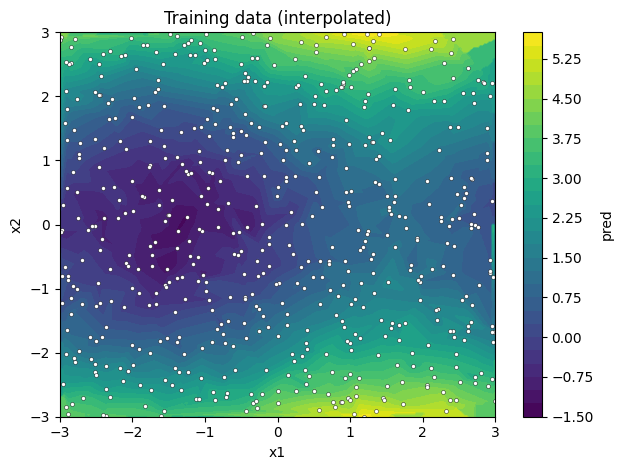

In [21]:
from scipy.interpolate import griddata

def interpolate_train(X_grid):
  """Interpolate y between the training points; nearest neighbour outside their convex hull."""
  y_lin = griddata(ds.train.X, ds.train.y, X_grid, method='linear')
  y_near = griddata(ds.train.X, ds.train.y, X_grid, method='nearest')
  return np.where(np.isnan(y_lin), y_near, y_lin)

plot_surface_2d(interpolate_train, (-3, 3), (-3, 3),
                title='Training data (interpolated)', filename='train_surface.png')

# the actual training points on top of the interpolated surface
plt.scatter(ds.train.X[:, 0], ds.train.X[:, 1], c='white', edgecolors='black', s=8, linewidths=0.3)
plt.show()

**Observations:**

The response varies smoothly over the input space and has a simple structure:

- **Along $x_1$, $y$ oscillates like a wave.** It is lowest around $x_1 \approx -1.5$ and highest around $x_1 \approx 1.5$.
- **Along $x_2$, $y$ is roughly symmetric around 0 and increases with $|x_2|$**, like a parabola.

Together, this gives a minimum of about $-1.3$ near $(x_1, x_2) \approx (-1.5, 0)$ and the largest values (about 5.6) at the top and bottom edges near $x_1 \approx 1.5$. The shape looks like $\sin(x_1) + c \, x_2^2$; we check this in (d). On top of this smooth structure, the interpolated surface is slightly irregular, which comes from noise in $y$. The training points cover the square $[-3, 3]^2$ fairly evenly.

(The colour bar label "pred" is hard-coded in the provided `plot_surface_2d`; here the colours show the observed $y$.)

### (b) Random Kitchen Sink with Ridge Regression
Implement and fit an RKS model to the given dataset with ridge regression. You will need to vary one of the key hyperparameters while keeping others fixed at reasonable defaults. Possible hyperparameters include:

- the number of random features $h$,
- the kernel scale parameter $\sigma$, or
- the ridge regularization strength $\lambda$.

Perform a hyperparameter sweep over your chosen parameter and record both the training and validation losses (MSE). Plot the losses as a function of the hyperparameter (two plots, one for training and one for validation loss), and select the best hyper-param based on the validation loss.

**RKS model definition**

The model is implemented in `RandomKitchenSinks` in `models.py`.

In [22]:
# show the implementation from models.py
import inspect
print(inspect.getsource(RandomKitchenSinks))
print(inspect.getsource(sweep_rks_model))

class RandomKitchenSinks:
    """
    Random Kitchen Sinks featurization with ridge regression.
    """
    def __init__(self, D: int = 1000, sigma: float = 1.0, ridge_lambda: float = 1e-3, d: int = 2, random_state: int = 0):
        """
        Potential hyper-parameters you can consider (feel free to add more):
            D: total number of random features (= 2h in the assignment text; if you use both sin and cos features, D should be an even number)
            sigma: scale parameter for the RBF kernel, used for initializing the weight parameters
            ridge_lambda: ridge regularization strength
            d: dimension of the covariates
            random_state: seed for drawing the random features
        """
        # h pairs of feature functions (sin and cos) => 2h = D
        assert D % 2 == 0, 'D must be even (h sin/cos pairs)'

        self.D = D
        self.sigma = sigma
        self.ridge_lambda = ridge_lambda

        rng = np.random.default_rng(random_state)
     

**Hyperparameter sweep**

**Coarse sweep over a wide range of $\sigma$**, to find the region of the minimum. The fine sweep below then zooms in on it.

In [23]:
sigma_coarse = [0.01, 0.1, 0.3, 0.5, 1, 2, 5, 10, 20, 50, 100]

_, _, _, coarse_train, coarse_val = sweep_rks_model(sigma_coarse, ds.train.X, ds.train.y, ds.val.X, ds.val.y)
pd.DataFrame({'sigma': sigma_coarse, 'train MSE': coarse_train, 'val MSE': coarse_val}).round(4)

,sigma,train MSE,val MSE
0,0.01,0.0000,7.1904
1,0.10,0.0000,1.2232
2,0.30,0.0148,0.1166
3,0.50,0.0235,0.0518
4,1.00,0.0288,0.0446
5,2.00,0.0305,0.0380
6,5.00,0.0329,0.0361
7,10.00,0.0362,0.0374
8,20.00,0.0385,0.0409
9,50.00,0.1900,0.1967


**Fine sweep** between $\sigma = 1$ and $\sigma = 10$

In [24]:
sigma_vec = np.linspace(1, 10, 91)

best_rks, best_rks_val_mse, best_sigma, MSE_train_vec_rks, MSE_validation_vec_rks = sweep_rks_model(
  sigma_vec, ds.train.X, ds.train.y, ds.val.X, ds.val.y)

print(f'Best sigma: {best_sigma:.4f}, validation MSE: {best_rks_val_mse:.4f}')

Best sigma: 5.0000, validation MSE: 0.0361


**Training and validation loss vs. hyperparameter**

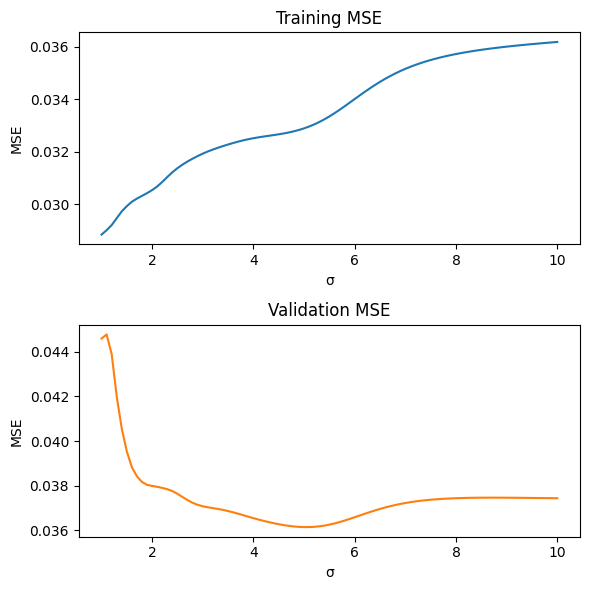

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(6, 6))

axes[0].plot(sigma_vec, MSE_train_vec_rks)
axes[0].set_title('Training MSE')

axes[1].plot(sigma_vec, MSE_validation_vec_rks, color='tab:orange')
axes[1].set_title('Validation MSE')

for ax in axes:
  ax.set_xlabel('σ')
  ax.set_ylabel('MSE')

plt.tight_layout()
plt.show()

**Answer:**

We sweep the kernel scale $\sigma$ and keep the other hyperparameters fixed: $D = 1000$ random features ($h = 500$ sine/cosine pairs), ridge strength $\lambda = 10^{-3}$ and the random seed. Since $w_j \sim \mathcal{N}(0, I/\sigma^2)$, $\sigma$ sets the frequencies of the random features: a small $\sigma$ gives large $w_j$ and therefore high-frequency, very wiggly features, while a large $\sigma$ gives features that vary only slowly over $[-3, 3]^2$. Because the seed is fixed, every $\sigma$ uses the same random draws, only rescaled, which is why the curves are smooth.

- **Coarse sweep:** for $\sigma \le 0.1$, the training MSE is essentially 0, while the validation MSE is between 1.2 and 7.2: the high-frequency features let the model interpolate the noise (overfitting). For $\sigma \ge 50$, both MSEs are about 0.2: the features are too smooth to follow the wave in $x_1$ (underfitting). The minimum lies between $\sigma = 2$ and $\sigma = 10$.
- **Fine sweep:** the training MSE increases steadily with $\sigma$, from 0.029 at $\sigma = 1$ to 0.036 at $\sigma = 10$, since the model becomes smoother and less flexible. The validation MSE first drops steeply, reaches its minimum at $\sigma = 5$, then rises slightly and levels off at about 0.0375. This is the usual bias–variance trade-off.

**Best hyperparameter: $\sigma = 5$, with a validation MSE of 0.0361.** The minimum is broad: every $\sigma$ between about 3 and 7 is within about 0.001 of it.

### (c) 1-Hidden Layer Multi-Layer Perceptron
Next, fit the same dataset using a one-hidden-layer MLP implemented in PyTorch or Jax (the provided starter code is in PyTorch). As before, you will choose one hyperparameter to vary (for example, the hidden layer dimension, learning rate, or batch size) and keep other hyperparameters fixed at default values. Plot the training and validation losses over the sweep and determine the best-performing configuration based on the validation loss.

**MLP model definition**

The model is implemented in `MLP` in `models.py` (imported as `OneHiddenLayerMLP`).

In [26]:
print(inspect.getsource(OneHiddenLayerMLP))
print(inspect.getsource(mlp_sweep))

class MLP(nn.Module):
    """1-hidden-layer MLP for regression."""
    def __init__(self, d_in: int, d_hidden: int = 128, d_out: int = 1, lr: float = 1e-3, batch_size: int = 128, num_epochs: int = 500, activation: str = "relu", device: str = "cpu", random_state: int = 0):
        """
        Potential hyper-parameters you can consider (feel free to add more):
            d_hidden: hidden dimension
            activation: activation function
            lr: learning rate
            batch_size: batch size
            num_epochs: number of passes over the training data
        """
        super().__init__()
        # CPU by default, so that the results do not depend on whether a GPU is available
        # (GPU and CPU round slightly differently; the CPU is not slower for a network this small)
        self.device = device
        self.lr = lr
        self.batch_size = batch_size
        self.num_epochs = num_epochs

        torch.manual_seed(random_state)  # same initial weights for every

**Hyperparameter sweep**

In [27]:
batch_size_vec = [10 * i for i in range(1, 21)]
batch_size_vec.sort()

best_mlp, best_mlp_val_mse, best_batch_size, MSE_train_vec_mlp, MSE_validation_vec_mlp = mlp_sweep(
  batch_size_vec, ds.train.X, ds.train.y, ds.val.X, ds.val.y)

print(f'Best batch size: {best_batch_size}, validation MSE: {best_mlp_val_mse:.4f}')

batch size 10: train MSE 0.0338, val MSE 0.0455


batch size 20: train MSE 0.0296, val MSE 0.0388


batch size 30: train MSE 0.0296, val MSE 0.0384


batch size 40: train MSE 0.0315, val MSE 0.0391


batch size 50: train MSE 0.0311, val MSE 0.0385


batch size 60: train MSE 0.0302, val MSE 0.0382


... (10 outputs left out)

batch size 170: train MSE 0.0328, val MSE 0.0404


batch size 180: train MSE 0.0328, val MSE 0.0401


batch size 190: train MSE 0.0340, val MSE 0.0411


batch size 200: train MSE 0.0344, val MSE 0.0406
Best batch size: 60, validation MSE: 0.0382


**Training and validation loss vs. hyperparameter**

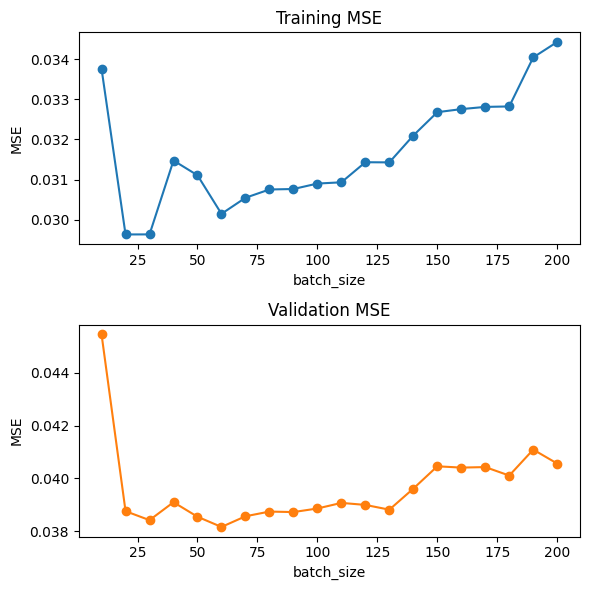

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(6, 6))

axes[0].plot(batch_size_vec, MSE_train_vec_mlp, marker='o')
axes[0].set_title('Training MSE')

axes[1].plot(batch_size_vec, MSE_validation_vec_mlp, marker='o', color='tab:orange')
axes[1].set_title('Validation MSE')

for ax in axes:
  ax.set_xlabel('batch_size')
  ax.set_ylabel('MSE')

plt.tight_layout()
plt.show()

**Answer:**

We sweep the batch size from 10 to 200 in steps of 10 and keep the other hyperparameters fixed: one hidden layer with 128 ReLU units, Adam with learning rate $10^{-3}$, 500 epochs, MSE loss, and the same initial weights for every batch size.

- **The training MSE mostly increases with the batch size**, from about 0.030 at batch sizes 20–30 to 0.034 at 200. With a fixed number of epochs, a larger batch means fewer gradient steps: 60 per epoch at batch size 10, but only 3 at batch size 200. With large batches, the network is therefore fitted less closely. Batch size 10 is an exception: its gradients are the noisiest, so the weights keep jumping around more at the end of training.
- **The validation MSE is worst at both ends.** It is highest at batch size 10 (0.0455), lowest and almost flat between 0.038 and 0.039 for batch sizes 20 to 130, and then rises to about 0.040–0.041 from batch size 140 on, where the network also fits the training data less closely.

**Best configuration: batch size 60, with a validation MSE of 0.0382.** However, every batch size from 20 to 130 is within 0.001 of it, so within this range the batch size hardly matters, and the choice of 60 is partly luck. Since we pick the minimum of 20 noisy estimates, its validation MSE is also slightly optimistic.

### (d) Comparison and visualization
Using the best-performing hyperparameters from the previous steps, refit both models and report the validation loss (MSE) of each. Discuss which approach performs better and why. The provided `test.csv` is *unlabeled* (it contains only $x_1, x_2$): produce predictions from both models on it and submit them as two CSV files, `rks_test_predictions.csv` and `mlp_test_predictions.csv`, one prediction per row in the same order as `test.csv`. Finally, visualize the fitted functions from the two models over the input space (we provide an example function to do this). Compare these surfaces with your visualization of the training data from part (a), and qualitatively explain how each model captures the underlying structure of the data.

**Refit with the best hyperparameters & validation MSE**

In [29]:
best_rks = RandomKitchenSinks(sigma = best_sigma).fit(ds.train.X, ds.train.y)
best_mlp = OneHiddenLayerMLP(d_in = 2, batch_size = best_batch_size).fit(ds.train.X, ds.train.y)

rks_val_mse = mean_squared_error(ds.val.y, best_rks.predict(ds.val.X))
mlp_val_mse = mean_squared_error(ds.val.y, best_mlp.predict(ds.val.X))
print(f'RKS (sigma = {best_sigma:.1f}):      validation MSE {rks_val_mse:.4f}')
print(f'MLP (batch size = {best_batch_size}): validation MSE {mlp_val_mse:.4f}')

RKS (sigma = 5.0):      validation MSE 0.0361
MLP (batch size = 60): validation MSE 0.0382


**How large is the difference, and how close are both models to the noise level?**

In [30]:
# paired comparison on the same validation points
diff = (ds.val.y - best_mlp.predict(ds.val.X)) ** 2 - (ds.val.y - best_rks.predict(ds.val.X)) ** 2
print(f'MLP minus RKS validation MSE: {diff.mean():.4f} (standard error {diff.std(ddof=1) / np.sqrt(len(diff)):.4f})')

# reference points: predicting the training mean, and a least-squares fit of y ~ 1 + sin(x1) + x2^2,
# a simple form that the training data appear to follow (see the plot in (a))
def reference_features(X):
  return np.column_stack([np.ones(len(X)), np.sin(X[:, 0]), X[:, 1] ** 2])

ref_coef, *_ = np.linalg.lstsq(reference_features(ds.train.X), ds.train.y, rcond=None)
print(f'Training mean:                     validation MSE {mean_squared_error(ds.val.y, np.full(len(ds.val.y), ds.train.y.mean())):.4f}')
print(f'y ~ {ref_coef[0]:.3f} + {ref_coef[1]:.3f} sin(x1) + {ref_coef[2]:.3f} x2^2: validation MSE '
      f'{mean_squared_error(ds.val.y, reference_features(ds.val.X) @ ref_coef):.4f}')

MLP minus RKS validation MSE: 0.0020 (standard error 0.0015)
Training mean:                     validation MSE 2.3966
y ~ -0.008 + 1.008 sin(x1) + 0.504 x2^2: validation MSE 0.0353


**Discussion: which model performs better and why?**

**Answer:**

With the best hyperparameters, **RKS reaches a validation MSE of 0.0361 and the MLP 0.0382**, so RKS performs slightly better (about 5% lower MSE). The difference is small, however:

- Both models are far better than predicting the training mean (2.40) and close to the noise level. A least-squares fit of the form $y \approx a + b \sin(x_1) + c \, x_2^2$, which the data appear to follow ($b \approx 1.01$, $c \approx 0.50$), reaches 0.0353. Both models therefore recover almost all of the structure, and what is left is mostly noise in $y$.
- On the same validation points, the MLP's MSE is higher by 0.0020, with a standard error of 0.0015, i.e. by about 1.3 standard errors. On 200 validation points, this is not conclusive. Both hyperparameters were also selected on this validation set, so both MSEs are slightly optimistic.

Still, it makes sense that RKS does at least as well here:

- **The target is smooth and low-dimensional** (2 inputs, 600 training points). RKS with $\sigma = 5$ approximates kernel ridge regression with a wide Gaussian kernel, i.e. a class of smooth functions, which matches the smooth target well.
- **RKS is easier to fit.** Its features are fixed, so only a ridge regression has to be solved, which is convex and solved exactly. The MLP is trained by stochastic gradient descent on a non-convex loss, so its result depends on the initialization, the order of the batches and the number of epochs, and we only tuned the batch size.
- **The MLP's extra flexibility does not help here.** Both models are linear models on top of features: RKS uses 1,000 fixed random features, while the MLP learns its 128 features. For a function as simple as this one, random smooth features are already sufficient, and learning the features from 600 noisy points mainly adds variance. In addition, ReLU units produce a piecewise linear function, which can only approximate the smooth curves with many linear pieces (see the surfaces below).

**Test set predictions**

In [31]:
# one prediction per row, in the same order as test.csv
rks_test_pred = best_rks.predict(ds.test.X)
mlp_test_pred = best_mlp.predict(ds.test.X)

pd.DataFrame({'y': rks_test_pred}).to_csv('rks_test_predictions.csv', index=False)
pd.DataFrame({'y': mlp_test_pred}).to_csv('mlp_test_predictions.csv', index=False)

print(f'Saved {len(rks_test_pred)} RKS and {len(mlp_test_pred)} MLP predictions ({len(ds.test.X)} rows in test.csv)')

Saved 200 RKS and 200 MLP predictions (200 rows in test.csv)


**Fitted surfaces**

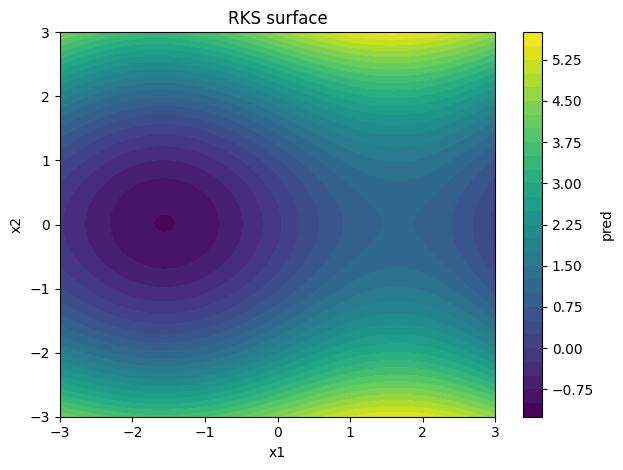

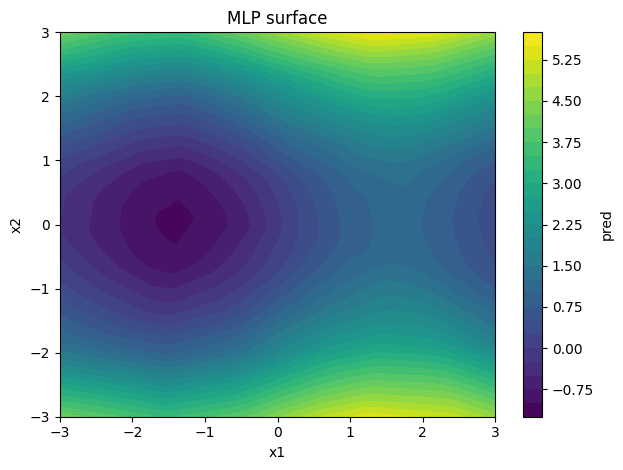

In [32]:
plot_surface_2d(best_rks.predict, (-3, 3), (-3, 3), title='RKS surface', filename='rks_surface.png')
plot_surface_2d(best_mlp, (-3, 3), (-3, 3), title='MLP surface', filename='mlp_surface.png')


**Discussion: how does each model capture the structure of the data?**

**Answer:**

Both surfaces reproduce the structure of the training data from (a): the minimum near $(-1.5, 0)$, the maxima at the top and bottom edges near $x_1 \approx 1.5$, the increase with $|x_2|$, and the lower values towards the right edge around $x_2 = 0$, where the wave in $x_1$ goes down again. Both surfaces are smoother than the interpolated training data, since the models average out the noise instead of passing through every training point. Visually, the two surfaces are almost identical, which matches their very similar validation MSEs.

The main difference is how each model builds its surface:

- **RKS** predicts a weighted sum of 1,000 smooth sine and cosine waves. Its surface is therefore smooth everywhere, with round, elliptical contours, e.g. around the minimum.
- **The MLP** predicts a weighted sum of 128 ReLU units. Each unit is zero on one side of a line through the input space and linear on the other side, so the surface is piecewise linear. This is visible as polygonal contours with corners, especially around the minimum and near the corners of the square.

At the edges and corners of $[-3, 3]^2$, the models only see training points on one side, so they partly extrapolate there. They still agree closely, since both follow the same overall shape.